# Notebook 6 — SOLUTION

## Short version

**Nothing changed.** Every unit is a homogeneous Poisson process with a constant
rate. The figure is the product of two things happening at once, and it is worth
separating them because only one of them is the famous bias:

1. **Averaging ratios is biased upward when the denominator is noisy.** Each
   post-event bin gets divided by a baseline estimated from a handful of spikes.
   Units that happen to have a low baseline estimate get a large ratio, and the
   right tail drags the mean above 1. The inflation is roughly
   `1 + 1/(number of baseline spikes)`. This is Jensen's inequality:
   E[X/Y] > E[X]/E[Y] when Y is variable.

2. **The baseline bins cannot show that bias, because they are pinned to exactly
   1 by construction.** The denominator is the mean of those same bins, so their
   mean ratio is 1 for every unit, exactly, with zero noise. So the flat,
   trustworthy-looking baseline is not evidence that the method is unbiased. It
   is an algebraic identity.

Together they manufacture the signature of a real response: a perfect baseline
and a sharp step at t = 0. The step is the boundary between the bins that are
pinned and the bins that are free to be inflated, not a physiological onset.

Note that the shifted histogram in the student notebook is not a defense. A
population-wide bias shifts the whole distribution, exactly as a real effect
would. Ruling out outliers does not rule out bias.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.stats import ttest_1samp

plt.rcParams['font.family']       = 'Arial'
plt.rcParams['font.sans-serif']   = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['pdf.fonttype']      = 42
plt.rcParams['ps.fonttype']       = 42


def band(ax, x, m, s, color, label=None):
    """Mean with a shaded +/- SEM band."""
    ax.fill_between(x, m - s, m + s, color=color, alpha=0.25, lw=0, zorder=2)
    ax.plot(x, m, '-', color=color, lw=1.8, zorder=3, label=label)


In [2]:
d = np.load('data/data.npz')
spike_times    = d['spike_times'].astype(float)    # (n_spikes,) s, ascending
spike_clusters = d['spike_clusters'].astype(int)   # (n_spikes,) unit index per spike
event_times    = d['event_times']                  # (n_events,) s
n_neurons      = int(d['n_neurons'])
duration       = float(d['recording_duration'])    # s
n_events       = len(event_times)
print(f'{n_neurons} units, {n_events} events, {len(spike_times):,} spikes, '
      f'{duration:.1f} s recording')

session_rate = np.bincount(spike_clusters, minlength=n_neurons) / duration
print(f'session-wide firing rate: median {np.median(session_rate):.2f}, '
      f'range {session_rate.min():.2f} to {session_rate.max():.0f} spikes/s')


2000 units, 20 events, 559,703 spikes, 52.1 s recording
session-wide firing rate: median 3.07, range 0.48 to 158 spikes/s


In [3]:
WIN = (-0.30, 0.70)      # s relative to the event
BIN = 0.05               # s, PSTH bin width

def psth_counts(win, bin_w, trials=None):
    """Spike counts in bins relative to each event -> (units, trials, bins)."""
    edges  = np.arange(win[0], win[1] + bin_w / 2, bin_w)
    events = event_times if trials is None else event_times[trials]
    counts = np.zeros((n_neurons, len(events), len(edges) - 1))
    for j, t_ev in enumerate(events):
        rel = spike_times - t_ev                       # spike times re: this event
        sel = (rel >= win[0]) & (rel < win[1])
        b   = np.floor((rel[sel] - win[0]) / bin_w).astype(int)
        # np.add.at, NOT `counts[...] += 1`: fancy-index += drops repeated
        # indices, so a unit with two spikes in one bin on one trial would
        # be counted once. That silently undercounts high-rate units.
        np.add.at(counts[:, j, :], (spike_clusters[sel], b), 1)
    return counts, edges

counts, edges = psth_counts(WIN, BIN)
t_bin       = edges[:-1] + BIN / 2       # bin centers, s
rate        = counts.mean(1) / BIN       # (units, bins) firing rate, spikes/s
is_baseline = t_bin < 0                  # pre-event bins define the baseline
print(f'{rate.shape[1]} bins of {BIN*1000:.0f} ms: '
      f'{is_baseline.sum()} baseline, {(~is_baseline).sum()} post-event')


20 bins of 50 ms: 6 baseline, 14 post-event


## Evidence 1 — Subtract instead of divide and the response disappears

The cleanest test. Keep everything the same, including correcting each unit by
its own baseline, and change one operation: subtract the baseline (spikes/s)
instead of dividing by it.

Both versions have an immaculate baseline for the same algebraic reason. Only the
ratio has a step.

The middle panel is the raw population rate with no normalization at all. Its
error band is wide because units differ hugely in rate, which is exactly why
people normalize in the first place. The right panel is the sharp version of the
same test.


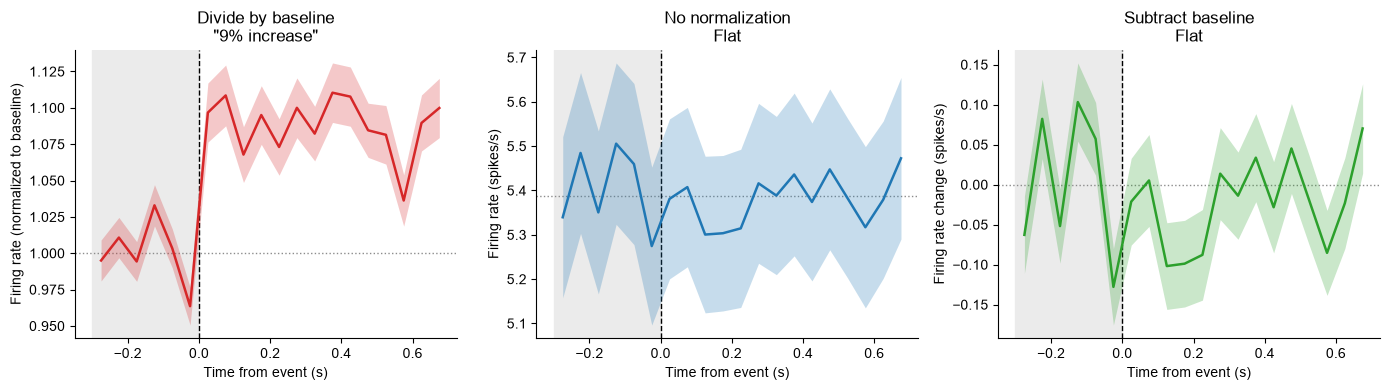

raw population rate      : 5.4023 -> 5.3800 spikes/s (-0.41%)
baseline-subtracted step : -0.0223 spikes/s, t = -0.86, p = 0.39   <- no change
ratio step               : +0.0881 (= +8.8%)         <- the artifact


In [4]:
baseline = rate[:, is_baseline].mean(1)
norm = rate / baseline[:, None]          # divide
diff = rate - baseline[:, None]          # subtract (spikes/s)

def panel(ax, X, ref, color):
    m = X.mean(0); s = X.std(0, ddof=1) / np.sqrt(X.shape[0])
    ax.axvspan(WIN[0], 0.0, color='0.92', zorder=0)
    ax.axhline(ref, color='0.55', ls=':', lw=1.0, zorder=1)
    ax.axvline(0.0, color='k', ls='--', lw=1.0, zorder=1)
    band(ax, t_bin, m, s, color)
    ax.set_xlabel('Time from event (s)')
    return m, s

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
panel(axes[0], norm, 1.0, 'tab:red')
axes[0].set_ylabel('Firing rate (normalized to baseline)')
axes[0].set_title('Divide by baseline\n"9% increase"')

panel(axes[1], rate, rate.mean(), 'tab:blue')
axes[1].set_ylabel('Firing rate (spikes/s)')
axes[1].set_title('No normalization\nFlat')

panel(axes[2], diff, 0.0, 'tab:green')
axes[2].set_ylabel('Firing rate change (spikes/s)')
axes[2].set_title('Subtract baseline\nFlat')
plt.tight_layout(); plt.show()

pre_r, post_r = rate[:, is_baseline].mean(1), rate[:, ~is_baseline].mean(1)
t_d, p_d = ttest_1samp(post_r - pre_r, 0.0)
print(f'raw population rate      : {pre_r.mean():.4f} -> {post_r.mean():.4f} spikes/s '
      f'({(post_r.mean()/pre_r.mean() - 1)*100:+.2f}%)')
print(f'baseline-subtracted step : {(post_r - pre_r).mean():+.4f} spikes/s, '
      f't = {t_d:.2f}, p = {p_d:.2f}   <- no change')
print(f'ratio step               : {norm[:, ~is_baseline].mean() - 1:+.4f} '
      f'(= {(norm[:, ~is_baseline].mean() - 1)*100:+.1f}%)         <- the artifact')


## Evidence 2 — The flat baseline is an identity, not a result

If the denominator is the mean of the baseline bins, then for **every** unit the
mean of its normalized baseline bins is exactly 1, whatever the spikes did. Sum
the ratios over the K baseline bins:

$$\sum_{k=1}^{K} \frac{r_k}{\frac{1}{K}\sum_j r_j} = \frac{\sum_k r_k}{\frac{1}{K}\sum_j r_j} = K$$

so the mean over baseline bins is 1, identically. There is no noise in that
number and no information in it. The same holds for the subtracted version, where
it is exactly 0.

This matters because the flat baseline is what makes the figure persuasive. It is
also the reason the step looks so sharp: t = 0 is the boundary between the bins
that are pinned and the bins that are free to be inflated.


In [5]:
pinned_ratio = norm[:, is_baseline].mean(1)      # one per unit
pinned_diff  = diff[:, is_baseline].mean(1)
print('Per-unit mean over the baseline bins, across all '
      f'{n_neurons} units:')
print(f'  divide   : min = {pinned_ratio.min():.12f}, max = {pinned_ratio.max():.12f}')
print(f'  subtract : min = {pinned_diff.min():+.2e}, max = {pinned_diff.max():+.2e}')
print(f'\n  spread across units (SD): {pinned_ratio.std():.2e}  <- exactly zero')


Per-unit mean over the baseline bins, across all 2000 units:
  divide   : min = 1.000000000000, max = 1.000000000000
  subtract : min = -5.92e-15, max = +2.37e-15

  spread across units (SD): 1.01e-16  <- exactly zero


## Evidence 3 — Two ways to unpin the baseline, and the step vanishes

If the step were a response, it would survive breaking the algebraic link between
numerator and denominator. It does not.

**Left: plot more pre-event time than the baseline window covers.** Keep the
baseline defined as [-0.3, 0) but plot back to -0.8 s. The bins before -0.3 s are
not in the denominator, so they are free to be inflated too, and they are, by the
same amount as the post-event bins. The "response" is present *before* the event.
Only the shaded window is flat.

**Right: estimate the baseline from held-out trials.** Odd trials give the
denominator, even trials give the PSTH. Now no bin is pinned, and the entire
trace, pre-event bins included, sits uniformly above 1. There is no step at all,
just a constant multiplicative bias.

Note that holding out trials does not remove the inflation. It only stops the
inflation from being hidden in the baseline. The bias comes from noise in the
denominator, which held-out data has just as much of.


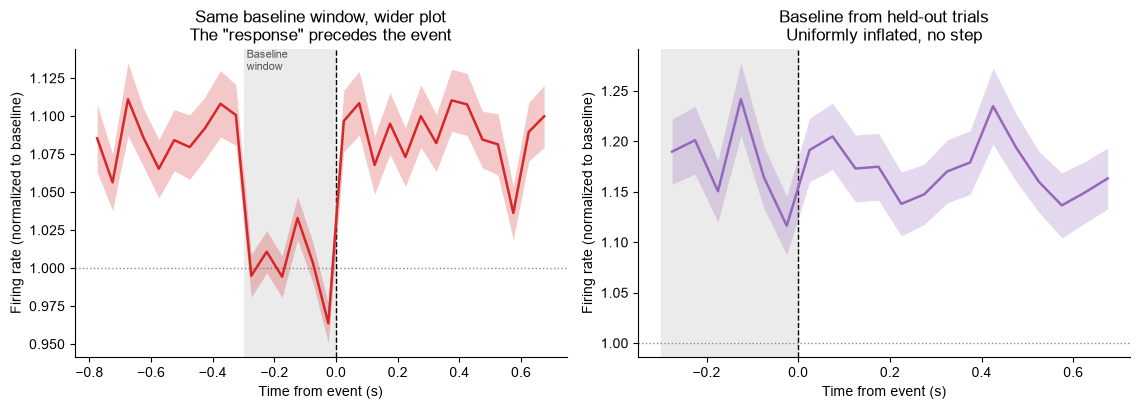

Wider plotting window, one baseline definition:
  before the baseline window (t < -0.3 s) : 1.0869
  inside the baseline window             : 1.000000  <- pinned
  after the event (t >= 0)               : 1.0881

Held-out baseline (1982 of 2000 units had >= 1 baseline spike):
  pre-event bins  : 1.1774
  post-event bins : 1.1727
  step            : -0.47 percentage points  <- gone


In [6]:
# --- Left: wider plotting window, same baseline definition ---
WIDE = (-0.80, 0.70)
counts_w, edges_w = psth_counts(WIDE, BIN)
rate_w  = counts_w.mean(1) / BIN
t_w     = edges_w[:-1] + BIN / 2
in_base = (t_w >= WIN[0]) & (t_w < 0.0)          # the original baseline window
norm_w  = rate_w / rate_w[:, in_base].mean(1)[:, None]

# --- Right: baseline from held-out (odd) trials, PSTH from even trials ---
odd, even = np.arange(1, n_events, 2), np.arange(0, n_events, 2)
c_base, _ = psth_counts((WIN[0], 0.0), BIN, trials=odd)
base_ho   = c_base.mean(1).mean(1) / BIN                 # (units,) spikes/s
c_psth, _ = psth_counts(WIN, BIN, trials=even)
rate_ho   = c_psth.mean(1) / BIN
ok        = base_ho > 0                                  # a few units get 0 spikes
norm_ho   = rate_ho[ok] / base_ho[ok, None]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

m = norm_w.mean(0); s = norm_w.std(0, ddof=1) / np.sqrt(n_neurons)
axes[0].axvspan(WIN[0], 0.0, color='0.92', zorder=0)
axes[0].axhline(1.0, color='0.55', ls=':', lw=1.0)
axes[0].axvline(0.0, color='k', ls='--', lw=1.0)
band(axes[0], t_w, m, s, 'tab:red')
axes[0].set_title('Same baseline window, wider plot\n'
                  'The "response" precedes the event')
axes[0].text(WIN[0] + 0.01, axes[0].get_ylim()[1], 'Baseline\nwindow',
             va='top', ha='left', fontsize=8, color='0.35')

m2 = norm_ho.mean(0); s2 = norm_ho.std(0, ddof=1) / np.sqrt(ok.sum())
axes[1].axvspan(WIN[0], 0.0, color='0.92', zorder=0)
axes[1].axhline(1.0, color='0.55', ls=':', lw=1.0)
axes[1].axvline(0.0, color='k', ls='--', lw=1.0)
band(axes[1], t_bin, m2, s2, 'tab:purple')
axes[1].set_title('Baseline from held-out trials\n'
                  'Uniformly inflated, no step')

for ax in axes:
    ax.set_xlabel('Time from event (s)')
    ax.set_ylabel('Firing rate (normalized to baseline)')
plt.tight_layout(); plt.show()

print('Wider plotting window, one baseline definition:')
print(f'  before the baseline window (t < -0.3 s) : {m[t_w < WIN[0]].mean():.4f}')
print(f'  inside the baseline window             : {m[in_base].mean():.6f}  <- pinned')
print(f'  after the event (t >= 0)               : {m[t_w >= 0].mean():.4f}')
print(f'\nHeld-out baseline ({ok.sum()} of {n_neurons} units had >= 1 baseline spike):')
print(f'  pre-event bins  : {m2[is_baseline].mean():.4f}')
print(f'  post-event bins : {m2[~is_baseline].mean():.4f}')
print(f'  step            : {(m2[~is_baseline].mean() - m2[is_baseline].mean())*100:+.2f} '
      f'percentage points  <- gone')


## Evidence 4 — Where the inflation lives, and summaries that avoid it

The units driving the mean up are the ones with small, poorly estimated
baselines. The fold-change distribution is right-skewed, so the mean sits above
the median, which is at 1.

The table below compares summaries. A caveat on the log transform: averaging
log fold-changes is often recommended as the fix, and it is much better, but it
is only unbiased when numerator and denominator are estimated from **equal
amounts of data**. Here the post window is 0.7 s and the baseline window is
0.3 s, so the noisier denominator still leaves a small positive bias. Match the
window lengths and it goes away.


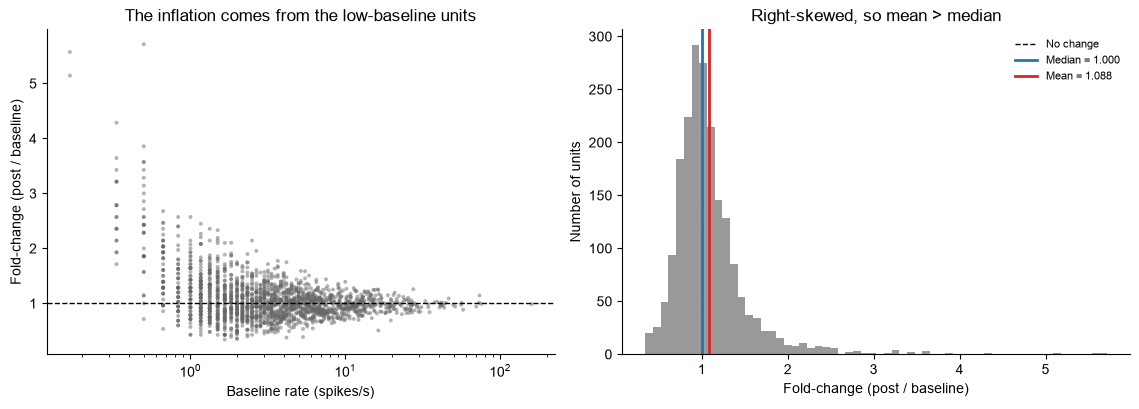

summary                                  0.7 s post   0.3 s post
----------------------------------------------------------------
mean fold-change (biased)                    1.0881       1.0907
median fold-change                           1.0000       1.0000
ratio of population means                    0.9959       0.9910
geometric mean (2 ** mean log2)              1.0243       0.9974
mean difference (spikes/s)                  -0.0223      -0.0485

Only the mean fold-change claims an increase. Everything that avoids
averaging a ratio with a noisy denominator says no change.


In [7]:
post_r = rate[:, ~is_baseline].mean(1)
fold   = post_r / pre_r
ok_f   = np.isfinite(fold) & (fold > 0)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].scatter(pre_r, fold, s=8, color='0.4', alpha=0.5, edgecolors='none')
axes[0].axhline(1.0, color='k', ls='--', lw=1.0)
axes[0].set_xscale('log')
axes[0].set_xlabel('Baseline rate (spikes/s)')
axes[0].set_ylabel('Fold-change (post / baseline)')
axes[0].set_title('The inflation comes from the low-baseline units')

axes[1].hist(fold[ok_f], bins=60, color='0.6')
axes[1].axvline(1.0, color='k', ls='--', lw=1.0, label='No change')
axes[1].axvline(np.median(fold[ok_f]), color='tab:blue', lw=2,
                label=f'Median = {np.median(fold[ok_f]):.3f}')
axes[1].axvline(fold[ok_f].mean(), color='tab:red', lw=2,
                label=f'Mean = {fold[ok_f].mean():.3f}')
axes[1].set_xlabel('Fold-change (post / baseline)')
axes[1].set_ylabel('Number of units')
axes[1].set_title('Right-skewed, so mean > median')
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

# Matched windows: 0.3 s post vs 0.3 s baseline
n_pre = int(is_baseline.sum())
post_matched = rate[:, n_pre:n_pre + n_pre].mean(1)
f_matched    = post_matched / pre_r
ok_m         = np.isfinite(f_matched) & (f_matched > 0)

print(f'{"summary":38s} {"0.7 s post":>12s} {"0.3 s post":>12s}')
print('-' * 64)
rows = [
    ('mean fold-change (biased)',
     fold[ok_f].mean(), f_matched[ok_m].mean()),
    ('median fold-change',
     np.median(fold[ok_f]), np.median(f_matched[ok_m])),
    ('ratio of population means',
     post_r.mean() / pre_r.mean(), post_matched.mean() / pre_r.mean()),
    ('geometric mean (2 ** mean log2)',
     2 ** np.log2(fold[ok_f]).mean(), 2 ** np.log2(f_matched[ok_m]).mean()),
]
for name, a, b in rows:
    print(f'{name:38s} {a:12.4f} {b:12.4f}')
print(f'{"mean difference (spikes/s)":38s} '
      f'{(post_r - pre_r).mean():12.4f} {(post_matched - pre_r).mean():12.4f}')
print('\nOnly the mean fold-change claims an increase. Everything that avoids')
print('averaging a ratio with a noisy denominator says no change.')


## Evidence 5 — The bias is estimation noise: more baseline data shrinks it

If the inflation were a real response it would not care how much data went into
the denominator. It cares a great deal.

Here the baseline is re-estimated from held-out inter-trial time (recording time
outside every plotted window, so numerator and denominator are independent), and
the amount of it is swept. The dashed line is the prediction
`1 + mean(1 / baseline spike count)`, the second-order approximation to the ratio
bias. It converges onto the data as the baseline grows, and overshoots badly when
the baseline holds only a handful of spikes, which is where a two-term Taylor
expansion has no business being trusted. What matters is that both curves head to
1: the elevation is a property of how much data went into the denominator, not of
the event.

The sweep runs on a fixed set of units, those with at least one baseline spike at
the shortest duration, so the population does not change along the curve.


20 inter-trial gaps, 31.2 s of held-out time


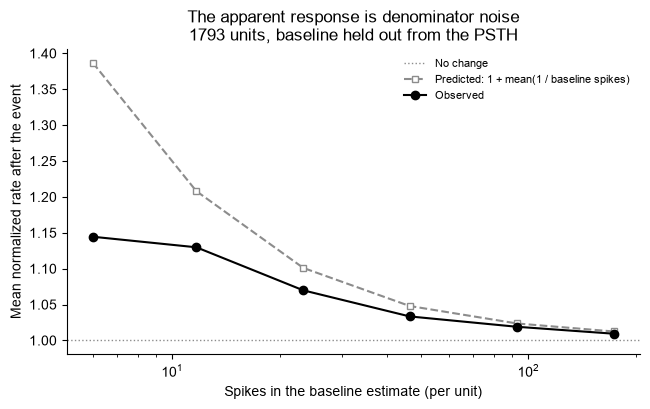

 held-out s  baseline spikes   observed  predicted
          1              6.0     1.1444     1.3869
          2             11.7     1.1297     1.2079
          4             23.3     1.0697     1.1009
          8             46.4     1.0334     1.0479
         16             92.8     1.0190     1.0236
         30            173.8     1.0093     1.0124


In [8]:
# Held-out time: everything not inside a plotted window
gaps = []
for i, t_ev in enumerate(event_times):
    start = t_ev + WIN[1]
    stop  = event_times[i + 1] + WIN[0] if i + 1 < n_events else duration
    if stop > start:
        gaps.append((start, stop))
print(f'{len(gaps)} inter-trial gaps, {sum(b - a for a, b in gaps):.1f} s of held-out time')

def baseline_from_heldout(total_s):
    """Spike counts in the first `total_s` s of held-out time -> (counts, seconds)."""
    cnt, used, need = np.zeros(n_neurons), 0.0, total_s
    for a, b in gaps:
        if need <= 1e-9:
            break
        take = min(b - a, need)
        sel  = (spike_times >= a) & (spike_times < a + take)
        np.add.at(cnt, spike_clusters[sel], 1)
        used += take
        need -= take
    return cnt, used

durations = np.array([1.0, 2.0, 4.0, 8.0, 16.0, 30.0])
swept     = [baseline_from_heldout(D) for D in durations]
keep      = np.all([c > 0 for c, _ in swept], axis=0)     # fixed population

obs, theory, nspk = [], [], []
for cnt, used in swept:
    b = cnt / used
    obs.append((rate[keep] / b[keep, None]).mean())
    theory.append(1 + np.mean(1.0 / cnt[keep]))
    nspk.append(cnt[keep].mean())

fig, ax = plt.subplots(figsize=(6.6, 4.2))
ax.axhline(1.0, color='0.55', ls=':', lw=1.0, label='No change')
ax.plot(nspk, theory, 's--', ms=5, color='0.55', mfc='white',
        label='Predicted: 1 + mean(1 / baseline spikes)')
ax.plot(nspk, obs, 'o-', ms=6, color='k', label='Observed')
ax.set_xscale('log')
ax.set_xlabel('Spikes in the baseline estimate (per unit)')
ax.set_ylabel('Mean normalized rate after the event')
ax.set_title(f'The apparent response is denominator noise\n'
             f'{keep.sum()} units, baseline held out from the PSTH')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'{"held-out s":>11s} {"baseline spikes":>16s} {"observed":>10s} {"predicted":>10s}')
for D, ns, o, th in zip(durations, nspk, obs, theory):
    print(f'{D:11.0f} {ns:16.1f} {o:10.4f} {th:10.4f}')


## The lesson

- **Averaging per-unit ratios is biased upward when the denominator is noisy.**
  A baseline-normalized PSTH divides by a baseline estimated from a few spikes.
  Small baselines blow up, the distribution is right-skewed, and the mean exceeds
  1 with no real change. The inflation is about `1 + 1/(baseline spike count)`,
  so it is worst for exactly the low-rate units that normalization was introduced
  to rescue.

- **A flat baseline in a baseline-normalized plot is not a control.** When the
  denominator is the mean of the baseline bins, those bins average to exactly 1
  by algebra, for every unit, no matter what. The immaculate baseline is the most
  persuasive part of the figure and it carries no information. Worse, it hides the
  bias in precisely the region a reader would use to judge it, which is what
  turns a uniform offset into an apparent onset at t = 0.

- **A shifted distribution does not distinguish a bias from an effect.** Checking
  that the result is not outlier-driven is good practice, and it rules out one
  alternative, but a population-wide bias moves the whole distribution just as a
  real effect would.

- **Diagnostics that work.** Subtract the baseline instead of dividing. Plot more
  pre-event time than the baseline window covers, so some pre-event bins are
  unpinned. Estimate the baseline from held-out trials. Report the mean
  difference in spikes/s, the ratio of population means, or a geometric mean over
  matched-length windows. If you must show fold-changes, show the distribution,
  not just its mean.

- **The bias is not specific to PSTHs.** Percent-change, normalized indices like
  (a-b)/(a+b), selectivity and modulation indices, dF/F with a short baseline,
  and any per-unit normalization that divides by a small noisy number all carry
  it. The rule of thumb: never let a quantity you are averaging have a noisy
  estimate in its denominator.
